In [1]:
# Cell 1 - project setup
from google.colab import drive
drive.mount("/content/drive")

from pathlib import Path
import random
import numpy as np

SEED = 42
random.seed(SEED)
np.random.seed(SEED)

# Large source files stay temporary in Colab.
LOCAL_ROOT = Path("/content/nsd_project")
RAW_DIR = LOCAL_ROOT / "raw"
RAW_DIR.mkdir(parents=True, exist_ok=True)

# Only small derived files/results go to Google Drive.
DRIVE_ROOT = Path("/content/drive/MyDrive/brain_signal_decoding")
FEATURE_DIR = DRIVE_ROOT / "features"
RESULT_DIR = DRIVE_ROOT / "results"

for folder in (FEATURE_DIR, RESULT_DIR):
    folder.mkdir(parents=True, exist_ok=True)

print("Temporary data:", RAW_DIR)
print("Drive outputs:", DRIVE_ROOT)

Mounted at /content/drive
Temporary data: /content/nsd_project/raw
Drive outputs: /content/drive/MyDrive/brain_signal_decoding


In [2]:
# Cell 2 - install reader and download the smallest NSD test set
!pip -q install nibabel

from pathlib import Path
from urllib.request import urlretrieve

MASK_URL = (
    "https://natural-scenes-dataset.s3.amazonaws.com/"
    "nsddata/ppdata/subj01/func1pt8mm/roi/nsdgeneral.nii.gz"
)

BETA_URL = (
    "https://natural-scenes-dataset.s3.amazonaws.com/"
    "nsddata_betas/ppdata/subj01/func1pt8mm/"
    "betas_fithrf_GLMdenoise_RR/betas_session01.nii.gz"
)

mask_file = RAW_DIR / "nsdgeneral.nii.gz"
beta_file = RAW_DIR / "betas_session01.nii.gz"

def download_if_needed(url, destination):
    if destination.exists() and destination.stat().st_size > 0:
        print(f"Already available: {destination.name}")
    else:
        print(f"Downloading: {destination.name}")
        urlretrieve(url, destination)
        print(f"Finished: {destination.name}")

download_if_needed(MASK_URL, mask_file)
download_if_needed(BETA_URL, beta_file)

for file in (mask_file, beta_file):
    print(f"{file.name}: {file.stat().st_size / 1024**2:.1f} MB")

Downloading: nsdgeneral.nii.gz
Finished: nsdgeneral.nii.gz
Downloading: betas_session01.nii.gz
Finished: betas_session01.nii.gz
nsdgeneral.nii.gz: 0.1 MB
betas_session01.nii.gz: 466.8 MB


In [3]:
# Cell 3 - verify spatial alignment and count usable voxels/trials
import nibabel as nib
import numpy as np

mask_img = nib.load(mask_file)
beta_img = nib.load(beta_file)

mask = mask_img.get_fdata(dtype=np.float32) > 0

print("Mask shape:", mask_img.shape)
print("Beta shape:", beta_img.shape)
print("Selected nsdgeneral voxels:", int(mask.sum()))
print("Trials in Session 1:", beta_img.shape[-1])

assert beta_img.shape[:3] == mask_img.shape, "Mask and beta volume do not align."
assert beta_img.ndim == 4, "Expected beta data with a trial dimension."
print("✓ Mask and beta volume align.")

Mask shape: (81, 104, 83)
Beta shape: (81, 104, 83, 750)
Selected nsdgeneral voxels: 15724
Trials in Session 1: 750
✓ Mask and beta volume align.


In [4]:
# Cell 3 - verify spatial alignment and count usable voxels/trials
import nibabel as nib
import numpy as np

mask_img = nib.load(mask_file)
beta_img = nib.load(beta_file)

mask = mask_img.get_fdata(dtype=np.float32) > 0

print("Mask shape:", mask_img.shape)
print("Beta shape:", beta_img.shape)
print("Selected nsdgeneral voxels:", int(mask.sum()))
print("Trials in Session 1:", beta_img.shape[-1])

assert beta_img.shape[:3] == mask_img.shape, "Mask and beta volume do not align."
assert beta_img.ndim == 4, "Expected beta data with a trial dimension."
print("✓ Mask and beta volume align.")

Mask shape: (81, 104, 83)
Beta shape: (81, 104, 83, 750)
Selected nsdgeneral voxels: 15724
Trials in Session 1: 750
✓ Mask and beta volume align.


In [5]:
# Cell 4 - download small trial/stimulus metadata only
from scipy.io import loadmat

METADATA_DIR = LOCAL_ROOT / "metadata"
METADATA_DIR.mkdir(exist_ok=True)

DESIGN_URL = (
    "https://natural-scenes-dataset.s3.amazonaws.com/"
    "nsddata/experiments/nsd/nsd_expdesign.mat"
)

STIM_INFO_URL = (
    "https://natural-scenes-dataset.s3.amazonaws.com/"
    "nsddata/experiments/nsd/nsd_stim_info_merged.csv"
)

design_file = METADATA_DIR / "nsd_expdesign.mat"
stim_info_file = METADATA_DIR / "nsd_stim_info_merged.csv"

download_if_needed(DESIGN_URL, design_file)
download_if_needed(STIM_INFO_URL, stim_info_file)

design = loadmat(design_file)
print("Experiment-design variables:")
for key, value in design.items():
    if not key.startswith("__"):
        print(f"  {key}: shape {np.shape(value)}")

print(f"\nStimulus metadata: {stim_info_file.stat().st_size / 1024**2:.1f} MB")

Downloading: nsd_expdesign.mat
Finished: nsd_expdesign.mat
Downloading: nsd_stim_info_merged.csv
Finished: nsd_stim_info_merged.csv
Experiment-design variables:
  basiccnt: shape (3, 40)
  masterordering: shape (1, 30000)
  sharedix: shape (1, 1000)
  stimpattern: shape (40, 12, 75)
  subjectim: shape (8, 10000)

Stimulus metadata: 10.8 MB


In [6]:
# Cell 5 - map the 750 Session 1 trials to NSD and COCO image IDs
import pandas as pd

stim_info = pd.read_csv(stim_info_file)

# NSD MATLAB metadata uses one-based IDs; Python arrays use zero-based IDs.
masterordering = design["masterordering"].squeeze().astype(int) - 1
subject01_images = design["subjectim"][0].astype(int) - 1

session01_nsd_ids = subject01_images[masterordering[:750]]

assert len(session01_nsd_ids) == 750
assert session01_nsd_ids.min() >= 0
assert session01_nsd_ids.max() < len(stim_info)

trial_map = stim_info.iloc[session01_nsd_ids].copy().reset_index(drop=True)
trial_map.insert(0, "trial_in_session", np.arange(1, 751))
trial_map.insert(1, "nsd_image_index", session01_nsd_ids)

print("Metadata columns:", stim_info.columns.tolist())
print("\nFirst five Session 1 trials:")
display(trial_map.head())

print("\nCOCO split counts:")
print(trial_map["cocoSplit"].value_counts(dropna=False))

Metadata columns: ['Unnamed: 0', 'cocoId', 'cocoSplit', 'cropBox', 'loss', 'nsdId', 'flagged', 'BOLD5000', 'shared1000', 'subject1', 'subject2', 'subject3', 'subject4', 'subject5', 'subject6', 'subject7', 'subject8', 'subject1_rep0', 'subject1_rep1', 'subject1_rep2', 'subject2_rep0', 'subject2_rep1', 'subject2_rep2', 'subject3_rep0', 'subject3_rep1', 'subject3_rep2', 'subject4_rep0', 'subject4_rep1', 'subject4_rep2', 'subject5_rep0', 'subject5_rep1', 'subject5_rep2', 'subject6_rep0', 'subject6_rep1', 'subject6_rep2', 'subject7_rep0', 'subject7_rep1', 'subject7_rep2', 'subject8_rep0', 'subject8_rep1', 'subject8_rep2']

First five Session 1 trials:


,trial_in_session,nsd_image_index,Unnamed: 0,cocoId,cocoSplit,cropBox,loss,nsdId,flagged,BOLD5000,...,subject5_rep2,subject6_rep0,subject6_rep1,subject6_rep2,subject7_rep0,subject7_rep1,subject7_rep2,subject8_rep0,subject8_rep1,subject8_rep2
0,1,46002,46002,412922,train2017,"(0, 0, 0.125, 0.125)",0.071429,46002,False,True,...,25837,1,12803,25837,1,12803,25837,1,12803,25837
1,2,61882,61882,474858,train2017,"(0, 0, 0.16640625, 0.16640625)",0.130435,61882,False,False,...,0,0,0,0,0,0,0,0,0,0
2,3,828,828,320696,val2017,"(0, 0, 0.16640625, 0.16640625)",0.000000,828,False,False,...,0,0,0,0,0,0,0,0,0,0
3,4,67573,67573,234676,train2017,"(0, 0, 0.16640625, 0.16640625)",0.000000,67573,False,False,...,0,0,0,0,0,0,0,0,0,0
4,5,16020,16020,301595,train2017,"(0.125, 0.125, 0, 0)",0.000000,16020,False,False,...,0,0,0,0,0,0,0,0,0,0



COCO split counts:
cocoSplit
train2017    720
val2017       30
Name: count, dtype: int64


In [7]:
# Cell 6 - download COCO object-category annotations (no images)
!pip -q install pycocotools

import zipfile
from urllib.request import urlretrieve

COCO_DIR = LOCAL_ROOT / "coco_annotations"
COCO_DIR.mkdir(exist_ok=True)

coco_zip = COCO_DIR / "annotations_trainval2017.zip"
train_instances = COCO_DIR / "instances_train2017.json"
val_instances = COCO_DIR / "instances_val2017.json"

COCO_ANNOTATIONS_URL = (
    "https://images.cocodataset.org/annotations/annotations_trainval2017.zip"
)

if not (train_instances.exists() and val_instances.exists()):
    print("Downloading official COCO annotations. This may take a few minutes...")
    urlretrieve(COCO_ANNOTATIONS_URL, coco_zip)

    with zipfile.ZipFile(coco_zip) as archive:
        for member in [
            "annotations/instances_train2017.json",
            "annotations/instances_val2017.json",
        ]:
            archive.extract(member, COCO_DIR)

    # Move the two extracted files into COCO_DIR directly.
    extracted_dir = COCO_DIR / "annotations"
    (extracted_dir / "instances_train2017.json").replace(train_instances)
    (extracted_dir / "instances_val2017.json").replace(val_instances)
    extracted_dir.rmdir()
    coco_zip.unlink()
else:
    print("COCO instance annotations already available.")

print(f"Train annotations: {train_instances.stat().st_size / 1024**2:.1f} MB")
print(f"Validation annotations: {val_instances.stat().st_size / 1024**2:.1f} MB")

URLError: <urlopen error [SSL: CERTIFICATE_VERIFY_FAILED] certificate verify failed: Hostname mismatch, certificate is not valid for 'images.cocodataset.org'. (_ssl.c:1032)>

In [8]:
# Cell 6 (replacement) - download and verify COCO instance annotations
!pip -q install pycocotools

import hashlib
import zipfile
from urllib.request import urlretrieve

COCO_DIR = LOCAL_ROOT / "coco_annotations"
COCO_DIR.mkdir(exist_ok=True)

coco_zip = COCO_DIR / "annotations_trainval2017.zip"
train_instances = COCO_DIR / "instances_train2017.json"
val_instances = COCO_DIR / "instances_val2017.json"

COCO_ANNOTATIONS_URL = (
    "http://images.cocodataset.org/annotations/annotations_trainval2017.zip"
)
EXPECTED_SHA256 = (
    "113a836d90195ee1f884e704da6304dfaaecff1f023f49b6ca93c4aaae470268"
)

# Remove the incomplete file created by the failed attempt.
if coco_zip.exists():
    coco_zip.unlink()

if not (train_instances.exists() and val_instances.exists()):
    print("Downloading COCO annotations...")
    urlretrieve(COCO_ANNOTATIONS_URL, coco_zip)

    downloaded_sha256 = hashlib.sha256(coco_zip.read_bytes()).hexdigest()
    assert downloaded_sha256 == EXPECTED_SHA256, "Checksum mismatch - stopping."
    print("✓ Download checksum verified.")

    with zipfile.ZipFile(coco_zip) as archive:
        for member in (
            "annotations/instances_train2017.json",
            "annotations/instances_val2017.json",
        ):
            archive.extract(member, COCO_DIR)

    extracted_dir = COCO_DIR / "annotations"
    (extracted_dir / "instances_train2017.json").replace(train_instances)
    (extracted_dir / "instances_val2017.json").replace(val_instances)
    extracted_dir.rmdir()
    coco_zip.unlink()

print(f"Train annotations: {train_instances.stat().st_size / 1024**2:.1f} MB")
print(f"Validation annotations: {val_instances.stat().st_size / 1024**2:.1f} MB")

✓ Download checksum verified.
Train annotations: 448.0 MB
Validation annotations: 19.1 MB


In [9]:
# Cell 7 - create dominant COCO-supercategory labels for Session 1
from collections import Counter
import json
from pycocotools.coco import COCO

coco_train = COCO(str(train_instances))
coco_val = COCO(str(val_instances))
coco_by_split = {
    "train2017": coco_train,
    "val2017": coco_val,
}

SUPER_CATEGORIES = [
    "accessory", "animal", "appliance", "electronic",
    "food", "furniture", "indoor", "kitchen",
    "outdoor", "person", "sports", "vehicle",
]
label_to_id = {name: index for index, name in enumerate(SUPER_CATEGORIES)}

def dominant_supercategory(coco_id, coco_split):
    coco = coco_by_split[coco_split]
    annotation_ids = coco.getAnnIds(imgIds=[int(coco_id)])
    annotations = coco.loadAnns(annotation_ids)

    supercategories = [
        coco.cats[annotation["category_id"]]["supercategory"]
        for annotation in annotations
    ]

    if not supercategories:
        return None

    counts = Counter(supercategories)
    largest_count = max(counts.values())
    winners = [
        category for category, count in counts.items()
        if count == largest_count
    ]

    # A tie is ambiguous, so exclude it.
    return winners[0] if len(winners) == 1 else None

trial_map["dominant_supercategory"] = [
    dominant_supercategory(coco_id, coco_split)
    for coco_id, coco_split in zip(
        trial_map["cocoId"], trial_map["cocoSplit"]
    )
]

labeled_trials = trial_map.dropna(
    subset=["dominant_supercategory"]
).copy()

labeled_trials["label_id"] = (
    labeled_trials["dominant_supercategory"].map(label_to_id).astype(int)
)

label_file = FEATURE_DIR / "nsd_session01_trial_labels.csv"
labeled_trials.to_csv(label_file, index=False)

with open(DRIVE_ROOT / "nsd_label_mapping.json", "w") as file:
    json.dump(label_to_id, file, indent=2)

print(f"Original trials: {len(trial_map)}")
print(f"Usable labeled trials: {len(labeled_trials)}")
print(f"Dropped ambiguous/unlabeled trials: {len(trial_map) - len(labeled_trials)}")
print("\nClass distribution:")
print(labeled_trials["dominant_supercategory"].value_counts().sort_index())
print(f"\nSaved labels: {label_file}")

loading annotations into memory...
Done (t=32.01s)
creating index...
index created!
loading annotations into memory...
Done (t=1.10s)
creating index...
index created!
Original trials: 750
Usable labeled trials: 550
Dropped ambiguous/unlabeled trials: 200

Class distribution:
dominant_supercategory
accessory       6
animal         88
appliance       5
electronic     20
food           40
furniture      41
indoor         43
kitchen        61
outdoor        14
person        120
sports         21
vehicle        91
Name: count, dtype: int64

Saved labels: /content/drive/MyDrive/brain_signal_decoding/features/nsd_session01_trial_labels.csv


In [10]:
# Cell 8 - extract Session 1 ROI features and save the derived dataset
import gc

# Load beta values as float32 only once, then apply the ROI mask.
beta_4d = beta_img.get_fdata(dtype=np.float32)

# Result: one row per trial, one column per nsdgeneral voxel.
X_all_trials = beta_4d[mask, :].T.copy()

# Release the large full-brain data immediately.
del beta_4d
beta_img.uncache()
gc.collect()

selected_trial_indices = (
    labeled_trials["trial_in_session"].to_numpy(dtype=int) - 1
)

X_session01 = X_all_trials[selected_trial_indices].astype(np.float32, copy=False)
y_session01 = labeled_trials["label_id"].to_numpy(dtype=np.int64)

assert X_session01.shape == (len(labeled_trials), int(mask.sum()))
assert np.isfinite(X_session01).all(), "Found non-finite beta values."

session01_feature_file = FEATURE_DIR / "nsd_session01_features.npz"

np.savez_compressed(
    session01_feature_file,
    X=X_session01,
    y=y_session01,
    subject=np.full(len(y_session01), "subj01"),
    session=np.ones(len(y_session01), dtype=np.int16),
    trial_in_session=labeled_trials["trial_in_session"].to_numpy(dtype=np.int16),
    nsd_image_index=labeled_trials["nsd_image_index"].to_numpy(dtype=np.int32),
    coco_id=labeled_trials["cocoId"].to_numpy(dtype=np.int64),
    class_names=np.array(SUPER_CATEGORIES),
)

print("Feature matrix shape:", X_session01.shape)
print("Label vector shape:", y_session01.shape)
print(f"Saved feature file: {session01_feature_file}")
print(f"Saved size: {session01_feature_file.stat().st_size / 1024**2:.1f} MB")

Feature matrix shape: (550, 15724)
Label vector shape: (550,)
Saved feature file: /content/drive/MyDrive/brain_signal_decoding/features/nsd_session01_features.npz
Saved size: 17.3 MB


In [11]:
# Cell 9 - create feature files for Sessions 2, 3, and 4
BETA_URL_TEMPLATE = (
    "https://natural-scenes-dataset.s3.amazonaws.com/"
    "nsddata_betas/ppdata/subj01/func1pt8mm/"
    "betas_fithrf_GLMdenoise_RR/betas_session{session:02d}.nii.gz"
)

def build_labeled_trial_map(session_number):
    start = (session_number - 1) * 750
    stop = session_number * 750

    nsd_ids = subject01_images[masterordering[start:stop]]
    session_trials = stim_info.iloc[nsd_ids].copy().reset_index(drop=True)
    session_trials.insert(0, "trial_in_session", np.arange(1, 751))
    session_trials.insert(1, "nsd_image_index", nsd_ids)
    session_trials["dominant_supercategory"] = [
        dominant_supercategory(coco_id, coco_split)
        for coco_id, coco_split in zip(
            session_trials["cocoId"], session_trials["cocoSplit"]
        )
    ]

    session_trials = session_trials.dropna(
        subset=["dominant_supercategory"]
    ).copy()

    session_trials["label_id"] = (
        session_trials["dominant_supercategory"]
        .map(label_to_id)
        .astype(np.int64)
    )
    return session_trials

for session_number in (2, 3, 4):
    feature_file = FEATURE_DIR / f"nsd_session{session_number:02d}_features.npz"

    if feature_file.exists() and feature_file.stat().st_size > 0:
        print(f"Session {session_number}: feature file already exists; skipping.")
        continue

    raw_beta_file = RAW_DIR / f"betas_session{session_number:02d}.nii.gz"
    beta_url = BETA_URL_TEMPLATE.format(session=session_number)

    download_if_needed(beta_url, raw_beta_file)

    session_trials = build_labeled_trial_map(session_number)
    session_img = nib.load(raw_beta_file)

    assert session_img.shape == beta_img.shape, "Unexpected beta-file shape."

    session_beta_4d = session_img.get_fdata(dtype=np.float32)
    X_all = session_beta_4d[mask, :].T.copy()

    selected_indices = (
        session_trials["trial_in_session"].to_numpy(dtype=int) - 1
    )
    X = X_all[selected_indices].astype(np.float32, copy=False)
    y = session_trials["label_id"].to_numpy(dtype=np.int64)

    assert np.isfinite(X).all(), f"Non-finite values in Session {session_number}"

    np.savez_compressed(
        feature_file,
        X=X,
        y=y,
        subject=np.full(len(y), "subj01"),
        session=np.full(len(y), session_number, dtype=np.int16),
        trial_in_session=session_trials["trial_in_session"].to_numpy(dtype=np.int16),
        nsd_image_index=session_trials["nsd_image_index"].to_numpy(dtype=np.int32),
        coco_id=session_trials["cocoId"].to_numpy(dtype=np.int64),
        class_names=np.array(SUPER_CATEGORIES),
    )

    print(
        f"Session {session_number}: {X.shape[0]} labeled trials, "
        f"{X.shape[1]} voxels, "
        f"{feature_file.stat().st_size / 1024**2:.1f} MB saved."
    )

    # Raw beta files are disposable after feature extraction.
    del session_beta_4d, X_all, X, y
    session_img.uncache()
    raw_beta_file.unlink()
    gc.collect()

Downloading: betas_session02.nii.gz
Finished: betas_session02.nii.gz
Session 2: 568 labeled trials, 15724 voxels, 17.6 MB saved.
Downloading: betas_session03.nii.gz
Finished: betas_session03.nii.gz
Session 3: 552 labeled trials, 15724 voxels, 17.4 MB saved.
Downloading: betas_session04.nii.gz
Finished: betas_session04.nii.gz
Session 4: 560 labeled trials, 15724 voxels, 17.4 MB saved.


In [12]:
# Cell 10 - combine sessions and define the final session-held-out split
session_feature_files = [
    FEATURE_DIR / f"nsd_session{session:02d}_features.npz"
    for session in (1, 2, 3, 4)
]

parts = [
    np.load(feature_file, allow_pickle=False)
    for feature_file in session_feature_files
]

X = np.concatenate([part["X"] for part in parts], axis=0).astype(np.float32)
y = np.concatenate([part["y"] for part in parts], axis=0).astype(np.int64)
subject = np.concatenate([part["subject"] for part in parts])
session = np.concatenate([part["session"] for part in parts]).astype(np.int16)
trial_in_session = np.concatenate(
    [part["trial_in_session"] for part in parts]
).astype(np.int16)
nsd_image_index = np.concatenate(
    [part["nsd_image_index"] for part in parts]
).astype(np.int32)
coco_id = np.concatenate([part["coco_id"] for part in parts]).astype(np.int64)

class_names = parts[0]["class_names"]

for part in parts:
    part.close()

train_mask = session <= 3
test_mask = session == 4

assert train_mask.sum() > 0 and test_mask.sum() > 0
assert set(y[test_mask]).issubset(set(y[train_mask])), (
    "A test class is absent from training data."
)

combined_feature_file = FEATURE_DIR / "nsd_features.npz"

np.savez_compressed(
    combined_feature_file,
    X=X,
    y=y,
    subject=subject,
    session=session,
    trial_in_session=trial_in_session,
    nsd_image_index=nsd_image_index,
    coco_id=coco_id,
    class_names=class_names,
)

print("Combined feature matrix:", X.shape)
print(f"Training trials (Sessions 1–3): {train_mask.sum()}")
print(f"Test trials (Session 4): {test_mask.sum()}")
print("Classes represented in training:", len(np.unique(y[train_mask])))
print("Classes represented in testing:", len(np.unique(y[test_mask])))
print(f"Saved team feature file: {combined_feature_file}")


Combined feature matrix: (2230, 15724)
Training trials (Sessions 1–3): 1670
Test trials (Session 4): 560
Classes represented in training: 12
Classes represented in testing: 12
Saved team feature file: /content/drive/MyDrive/brain_signal_decoding/features/nsd_features.npz


In [13]:
# Cell 11 - training-only z-score normalization and PCA
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA

X_train = X[train_mask]
X_test = X[test_mask]
y_train = y[train_mask]
y_test = y[test_mask]

# Fit normalization only on earlier sessions.
scaler = StandardScaler()
X_train_z = scaler.fit_transform(X_train)
X_test_z = scaler.transform(X_test)

MAX_PCA_COMPONENTS = 1000
n_components = min(
    MAX_PCA_COMPONENTS,
    X_train_z.shape[0] - 1,
    X_train_z.shape[1],
)

pca = PCA(
    n_components=n_components,
    svd_solver="randomized",
    random_state=SEED,
)

X_train_pca = pca.fit_transform(X_train_z).astype(np.float32)
X_test_pca = pca.transform(X_test_z).astype(np.float32)

print("PCA components used:", n_components)
print("Training matrix after PCA:", X_train_pca.shape)
print("Test matrix after PCA:", X_test_pca.shape)
print(
    "Variance explained:",
    f"{pca.explained_variance_ratio_.sum() * 100:.2f}%"
)

PCA components used: 1000
Training matrix after PCA: (1670, 1000)
Test matrix after PCA: (560, 1000)
Variance explained: 90.92%


In [14]:
# Cell 12 - required NSD decoding baselines and held-out-session metrics
from sklearn.linear_model import RidgeClassifier, LogisticRegression
from sklearn.metrics import accuracy_score
import pandas as pd

def top_k_accuracy(model, X_eval, y_eval, k=5):
    scores = model.decision_function(X_eval)
    top_k_positions = np.argsort(scores, axis=1)[:, -k:]
    top_k_classes = model.classes_[top_k_positions]
    return np.mean(np.any(top_k_classes == y_eval[:, None], axis=1))

models = {
    "RidgeClassifier": RidgeClassifier(alpha=1.0, class_weight="balanced"),
    "LogisticRegression": LogisticRegression(
        C=1.0,
        class_weight="balanced",
        solver="lbfgs",
        max_iter=2000,
        random_state=SEED,
    ),
}

result_rows = []

for model_name, model in models.items():
    print(f"Fitting {model_name}...")
    model.fit(X_train_pca, y_train)

    predictions = model.predict(X_test_pca)

    result_rows.append({
        "dataset": "NSD",
        "subject": "subj01",
        "train_sessions": "1-3",
        "test_sessions": "4",
        "model": model_name,
        "n_train": len(y_train),
        "n_test": len(y_test),
        "n_voxels": int(mask.sum()),
        "pca_components": n_components,
        "top1_accuracy": accuracy_score(y_test, predictions),
        "top5_accuracy": top_k_accuracy(model, X_test_pca, y_test, k=5),
        "random_seed": SEED,
    })

results = pd.DataFrame(result_rows)
results_file = RESULT_DIR / "nsd.csv"
results.to_csv(results_file, index=False)

display(
    results[
        ["model", "top1_accuracy", "top5_accuracy",
         "n_train", "n_test", "pca_components"]
    ]
)

print(f"Saved results: {results_file}")
print(f"Top-1 chance level for 12 classes: {1/12:.2%}")

Fitting RidgeClassifier...
Fitting LogisticRegression...


,model,top1_accuracy,top5_accuracy,n_train,n_test,pca_components
0,RidgeClassifier,0.458929,0.823214,1670,560,1000
1,LogisticRegression,0.464286,0.850000,1670,560,1000


Saved results: /content/drive/MyDrive/brain_signal_decoding/results/nsd.csv
Top-1 chance level for 12 classes: 8.33%


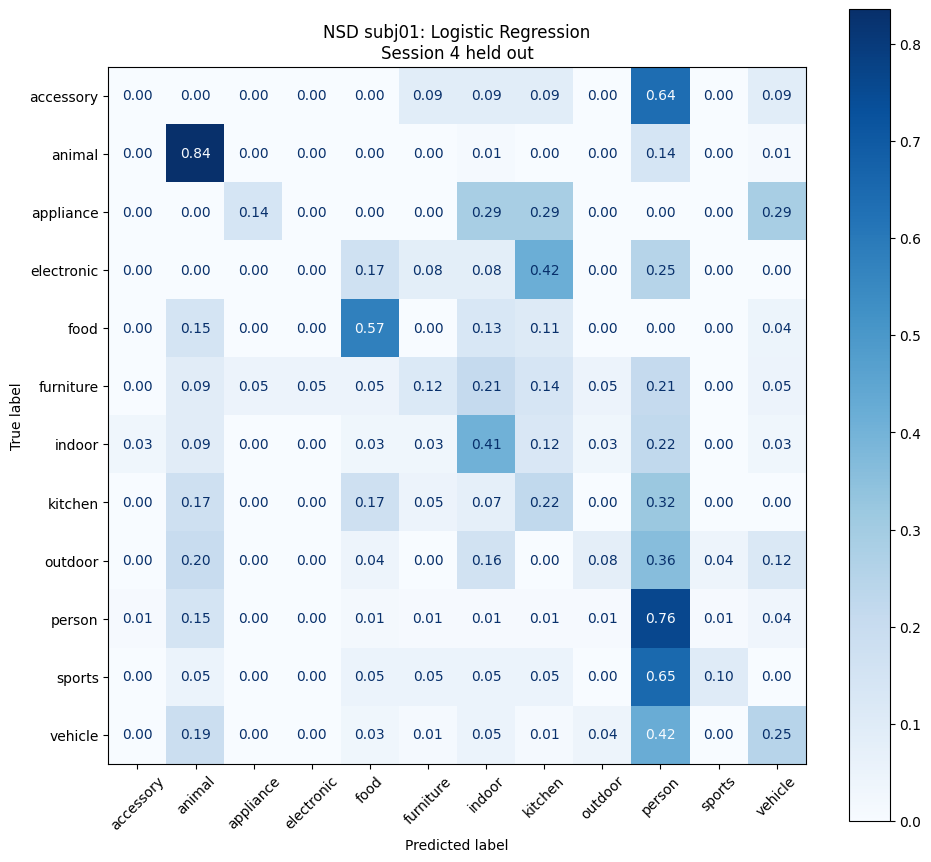

,precision,recall,f1-score,support
accessory,0.000000,0.000000,0.000000,11.0
animal,0.518248,0.835294,0.639640,85.0
appliance,0.333333,0.142857,0.200000,7.0
electronic,0.000000,0.000000,0.000000,12.0
food,0.586957,0.574468,0.580645,47.0
furniture,0.384615,0.116279,0.178571,43.0
indoor,0.276596,0.406250,0.329114,32.0
kitchen,0.257143,0.219512,0.236842,41.0
outdoor,0.200000,0.080000,0.114286,25.0
person,0.481818,0.757143,0.588889,140.0


Saved figure: /content/drive/MyDrive/brain_signal_decoding/results/nsd_logistic_confusion_matrix.png
Saved per-class metrics: /content/drive/MyDrive/brain_signal_decoding/results/nsd_logistic_per_class.csv


In [15]:
# Cell 13 - Logistic Regression confusion matrix and per-class metrics
from sklearn.metrics import ConfusionMatrixDisplay, classification_report
import matplotlib.pyplot as plt

best_model = models["LogisticRegression"]
y_pred = best_model.predict(X_test_pca)

figure_file = RESULT_DIR / "nsd_logistic_confusion_matrix.png"
per_class_file = RESULT_DIR / "nsd_logistic_per_class.csv"

fig, ax = plt.subplots(figsize=(10, 9))

ConfusionMatrixDisplay.from_predictions(
    y_test,
    y_pred,
    labels=np.arange(len(class_names)),
    display_labels=class_names,
    normalize="true",
    cmap="Blues",
    values_format=".2f",
    xticks_rotation=45,
    ax=ax,
)

ax.set_title("NSD subj01: Logistic Regression\nSession 4 held out")
plt.tight_layout()
fig.savefig(figure_file, dpi=200, bbox_inches="tight")
plt.show()

per_class = pd.DataFrame(
    classification_report(
        y_test,
        y_pred,
        labels=np.arange(len(class_names)),
        target_names=class_names,
        output_dict=True,
        zero_division=0,
    )
).T

per_class.to_csv(per_class_file)
display(per_class.loc[class_names, ["precision", "recall", "f1-score", "support"]])

print(f"Saved figure: {figure_file}")
print(f"Saved per-class metrics: {per_class_file}")

In [2]:
from google.colab import drive, files
from pathlib import Path
import zipfile

drive.mount("/content/drive")

drive_root = Path("/content/drive/MyDrive")

wanted = [
    "nsd.csv",
    "nsd_logistic_confusion_matrix.png",
    "nsd_logistic_per_class.csv",
]

found = {}
for name in wanted:
    matches = list(drive_root.rglob(name))
    found[name] = matches
    print(f"{name}: {matches}")

missing = [name for name, matches in found.items() if not matches]
if missing:
    raise FileNotFoundError(
        f"Missing: {missing}. Re-run Cells 12 and 13 to save the results again."
    )

bundle = Path("/content/member_a_github_files.zip")

with zipfile.ZipFile(bundle, "w", zipfile.ZIP_DEFLATED) as archive:
    for name in wanted:
        file = found[name][0]
        archive.write(file, arcname=f"results/{name}")

files.download(str(bundle))

Mounted at /content/drive
nsd.csv: [PosixPath('/content/drive/MyDrive/brain_signal_decoding/results/nsd.csv')]
nsd_logistic_confusion_matrix.png: [PosixPath('/content/drive/MyDrive/brain_signal_decoding/results/nsd_logistic_confusion_matrix.png')]
nsd_logistic_per_class.csv: [PosixPath('/content/drive/MyDrive/brain_signal_decoding/results/nsd_logistic_per_class.csv')]


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>